# **ML Lab 8**
#  Name : Mohisha Punwatkar
# Class : B(B1)
# Roll No : 12

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, confusion_matrix,recall_score,f1_score, classification_report , ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("/ai4i2020.csv")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [ ]:
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:

numerical_features = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]


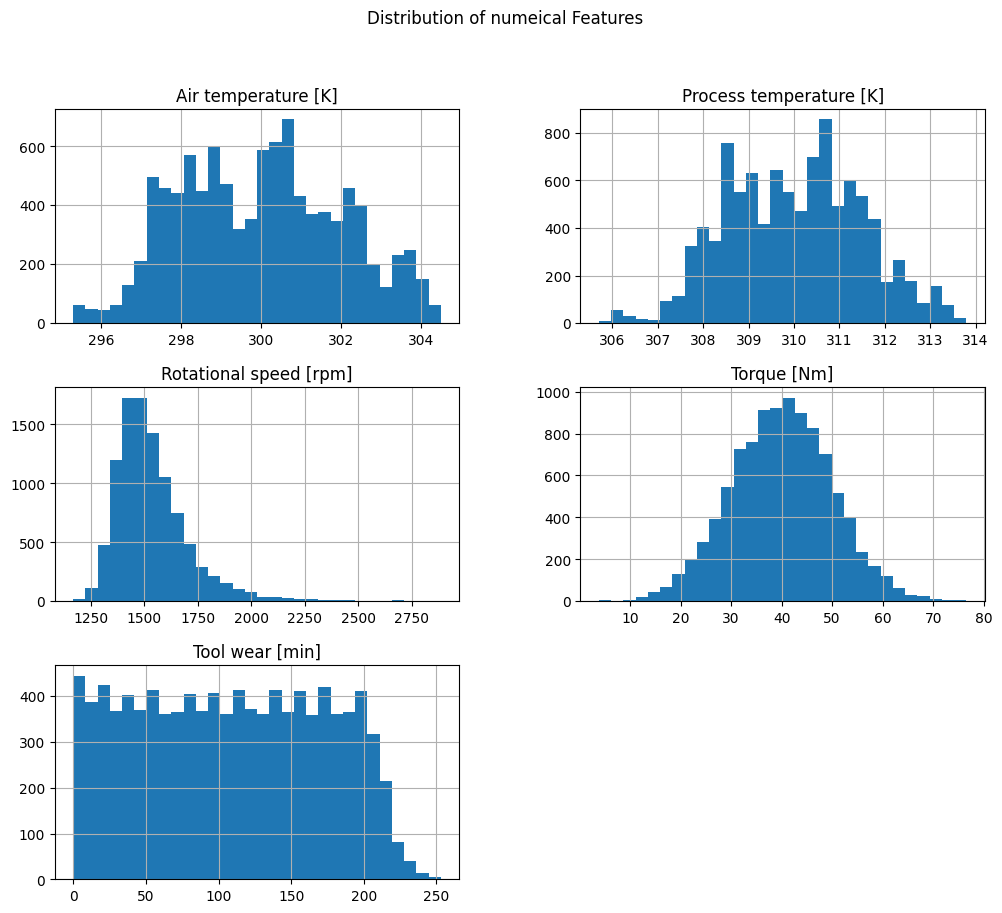

In [ ]:
df[numerical_features].hist(figsize=(12,10),bins=30)
plt.suptitle("Distribution of numeical Features")
plt.show()

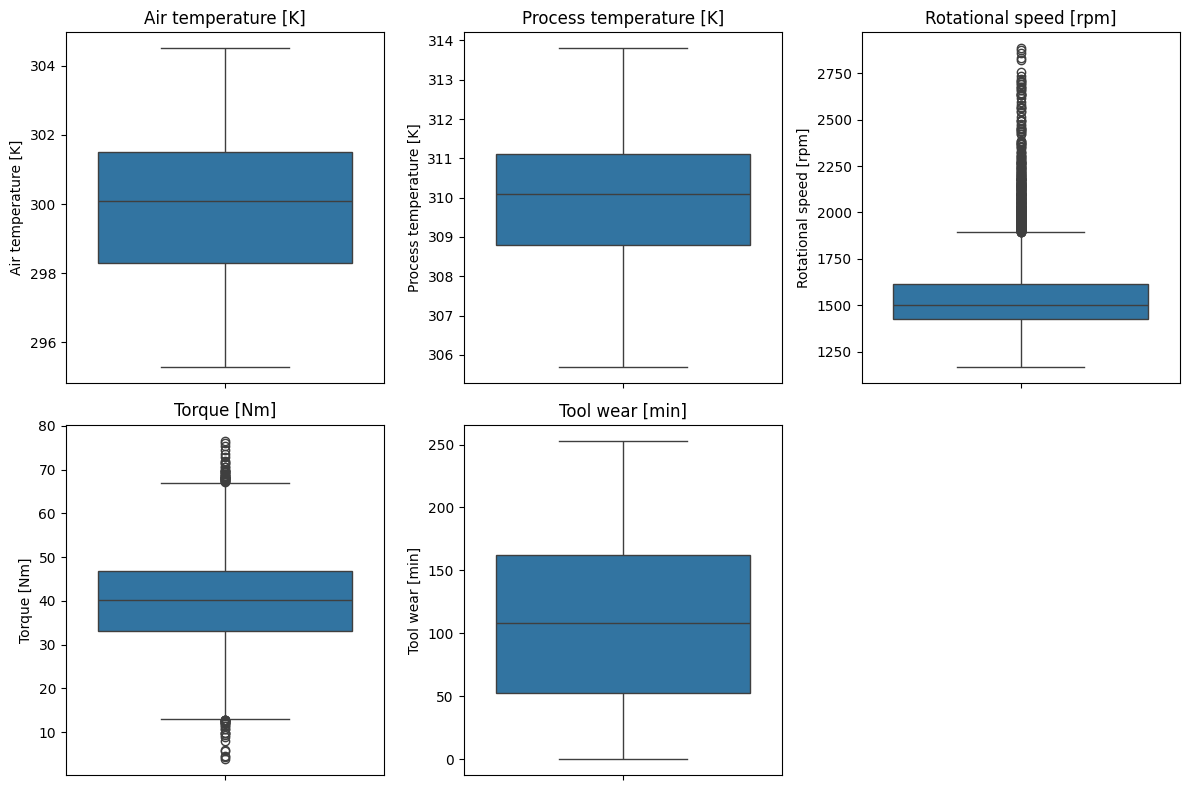

In [ ]:
plt.figure(figsize=(12,8))
for i, column in enumerate(numerical_features,1):
    plt.subplot(2,3,i)
    sns.boxplot(y=df[column])
    plt.title(column)
plt.tight_layout()
plt.show()

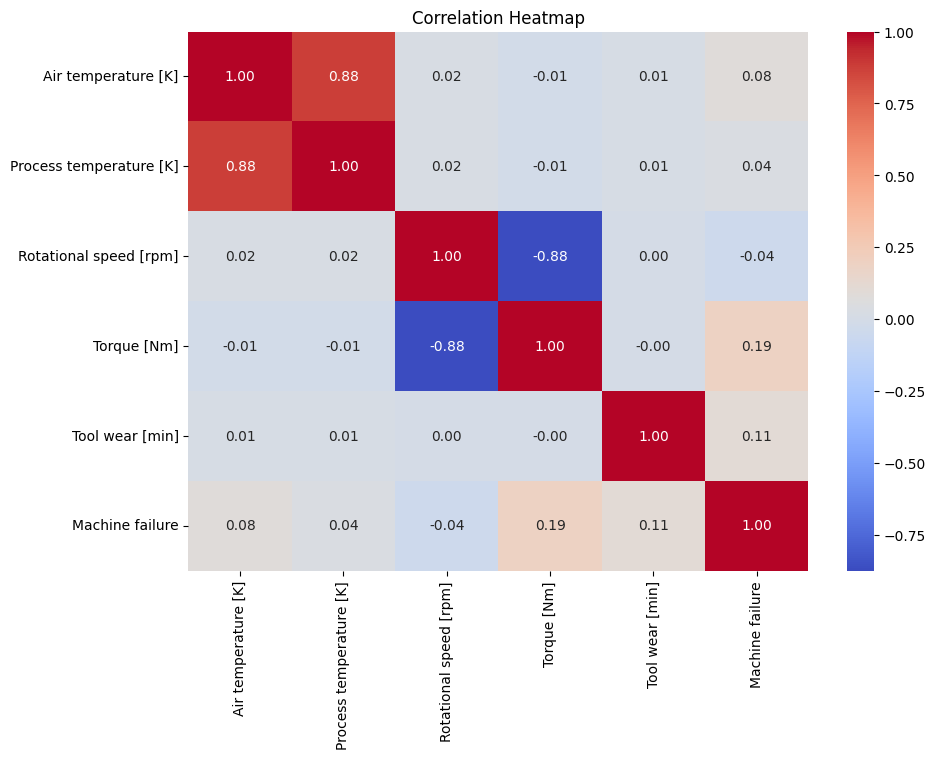

In [ ]:
plt.figure(figsize=(10,7))
correlation = df[numerical_features + ["Machine failure"]].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm' , fmt = ".2f")
plt.title("Correlation Heatmap")
plt.show()

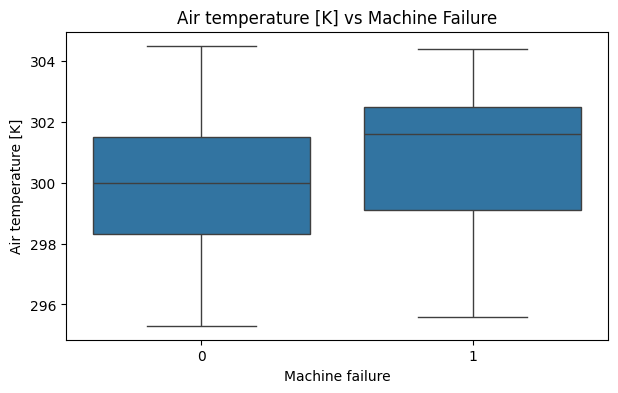

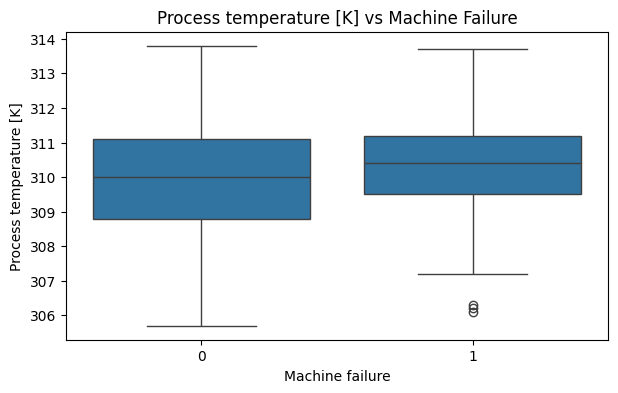

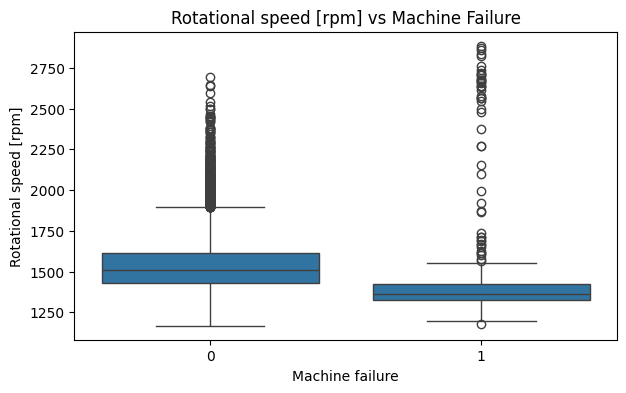

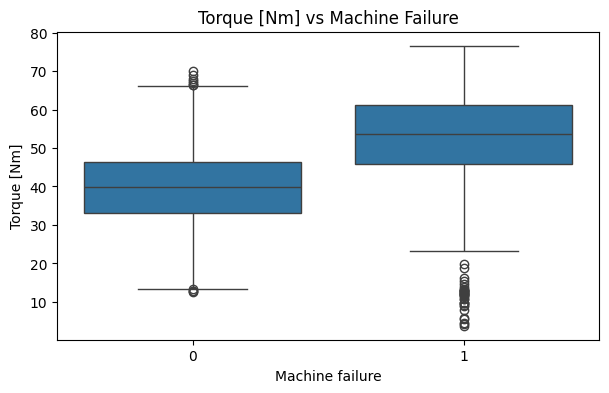

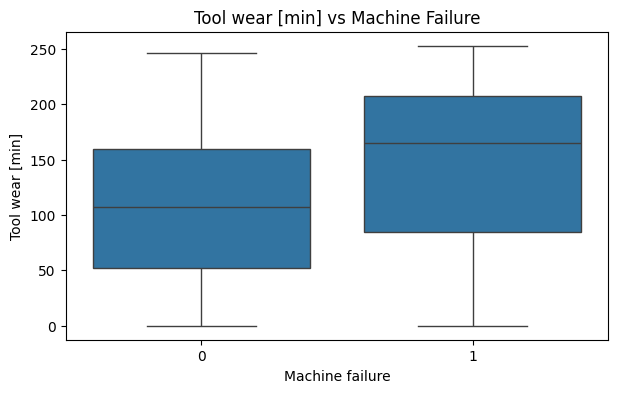

In [ ]:
for column in numerical_features:
    plt.figure(figsize=(7,4))
    sns.boxplot(x="Machine failure", y=column, data=df)
    plt.title(f"{column} vs Machine Failure")
    plt.show()

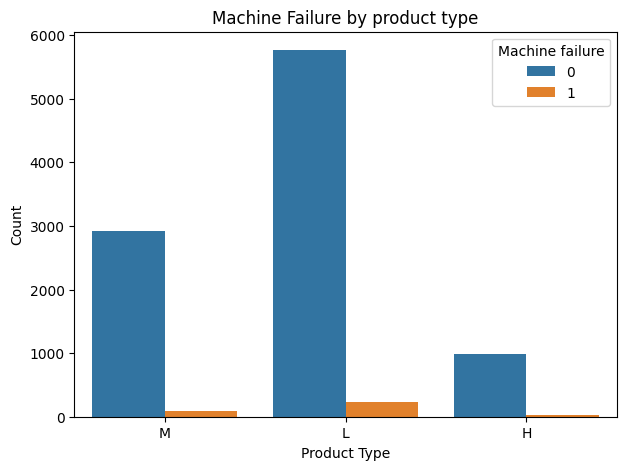

In [ ]:

plt.figure(figsize=(7,5))
sns.countplot(x="Type", hue="Machine failure", data=df)
plt.title("Machine Failure by product type")
plt.xlabel("Product Type")
plt.ylabel("Count")
plt.show()

In [ ]:
X = df[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]

In [ ]:
y = df["Machine failure"]

In [ ]:
print("input shape:", X.shape)
print("output shape:", y.shape)

input shape: (10000, 6)
output shape: (10000,)


In [ ]:
categorical_features = ["Type"]
numerical_features = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 8000
Testing samples: 2000


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown = "ignore"), categorical_features)
    ]
)

In [ ]:
linear_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="linear"))
    ]
)
linear_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='linear'))])

In [ ]:
y_pred_linear = linear_svm.predict(X_test)

In [ ]:
accuracy_linear = accuracy_score(y_test, y_pred_linear)
precision_linear = precision_score(y_test, y_pred_linear,zero_division=0)
recall_linear = recall_score(y_test, y_pred_linear,zero_division=0)
f1_linear = f1_score(y_test, y_pred_linear,zero_division=0)
print("Accuracy:", accuracy_linear)
print("Precision:", precision_linear)
print("Recall:", recall_linear)
print("F1 Score:", f1_linear)

Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [ ]:
print(
    classification_report(
        y_test, y_pred_linear, target_names=["No Failure", "Failure"],zero_division=0
    )
)

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



Text(0.5, 1.0, 'Confusion Matrix - Linear SVM')

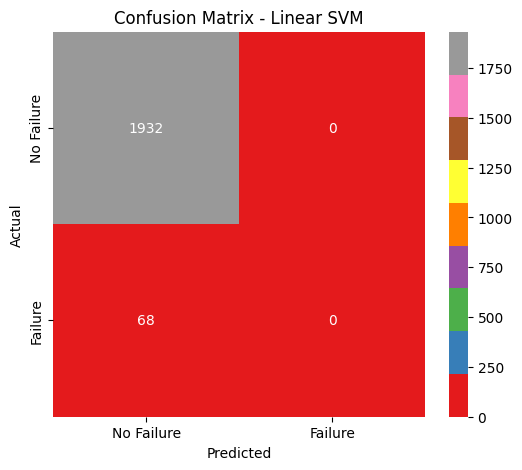

In [ ]:
cm_linear = confusion_matrix(y_test, y_pred_linear)
plt.figure(figsize=(6,5))
sns.heatmap(cm_linear, annot=True, fmt="d", cmap="Set1", xticklabels=["No Failure", "Failure"], yticklabels=["No Failure", "Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Linear SVM")


In [ ]:
rbf_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="rbf"))
    ]
)
rbf_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [ ]:
y_pred_rbf = rbf_svm.predict(X_test)

In [ ]:
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test, y_pred_rbf,zero_division=0)
recall_rbf = recall_score(y_test, y_pred_rbf,zero_division=0)
f1_rbf = f1_score(y_test, y_pred_rbf,zero_division=0)
print("RBF SVM Results")
print("Accuracy:", accuracy_rbf)
print("Precision:", precision_rbf)
print("Recall:", recall_rbf)
print("F1 Score:", f1_rbf)

RBF SVM Results
Accuracy: 0.972
Precision: 0.875
Recall: 0.20588235294117646
F1 Score: 0.3333333333333333


In [ ]:
print(classification_report(y_test, y_pred_rbf,target_names=["No failure","Failure"],zero_division=0))

              precision    recall  f1-score   support

  No failure       0.97      1.00      0.99      1932
     Failure       0.88      0.21      0.33        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.66      2000
weighted avg       0.97      0.97      0.96      2000



Text(0.5, 1.0, 'Confusion Matrix - RBF SVM')

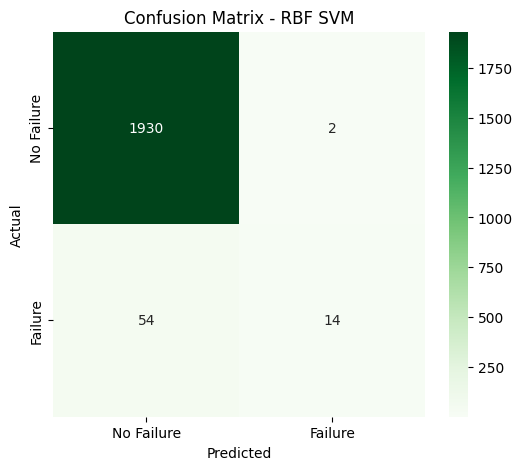

In [ ]:
cm_rbf = confusion_matrix(y_test, y_pred_rbf)
plt.figure(figsize=(6,5))
sns.heatmap(cm_rbf, annot=True, fmt="d", cmap="Greens", xticklabels=["No Failure", "Failure"], yticklabels=["No Failure", "Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - RBF SVM")

In [ ]:
comparison = pd.DataFrame({
    "Kernel": ["Linear SVM", "RBF"],
    "Accuracy": [accuracy_linear, accuracy_rbf],
    "Precision": [precision_linear, precision_rbf],
    "Recall": [recall_linear, recall_rbf],
    "F1 Score": [f1_linear, f1_rbf]
})
comparison

,Kernel,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.966,0.000,0.000000,0.000000
1,RBF,0.972,0.875,0.205882,0.333333


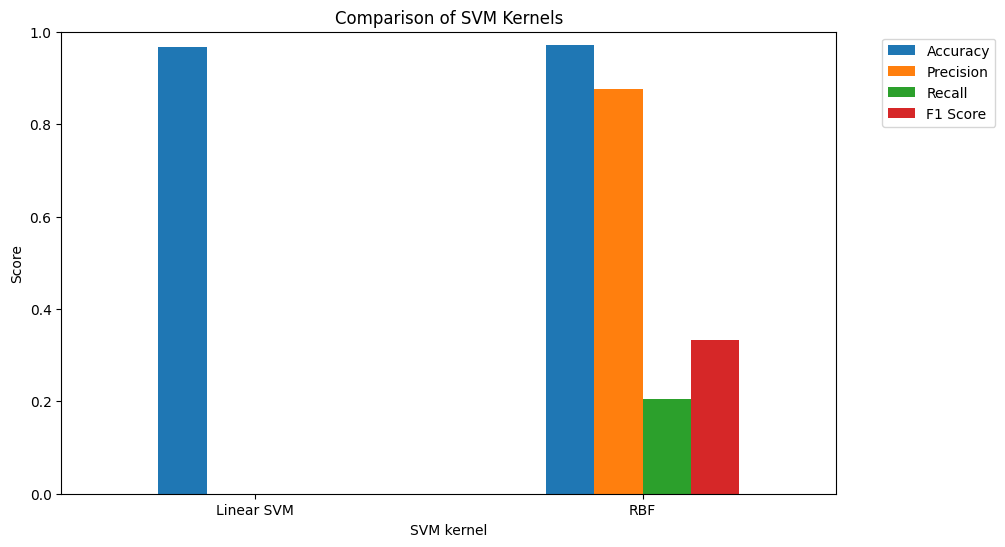

In [ ]:
comparison_plot = comparison.set_index("Kernel")
comparison_plot.plot(kind="bar",figsize=(10,6))
plt.title("Comparison of SVM Kernels")
plt.xlabel("SVM kernel")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout
plt.show()

In [ ]:
from sklearn.pipeline import Pipeline
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC())
    ]
)

In [ ]:
param_grid = [{"classifier__kernel": ["linear"],"classifier__C": [0.1,1,10,100]},
              {"classifier__kernel": ["rbf"], "classifier__C": [0.1,1,10,100],"classifier__gamma":["scale",0.01,0.1,1]}
              ]

In [ ]:
grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=5, scoring="f1",n_jobs=1,verbose=1)

In [ ]:
grid_search.fit(X_train, y_train)
print("GridSearchCV completed.")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
GridSearchCV completed.


In [ ]:
print("Best Parameters:")
print(grid_search.best_params_)

In [ ]:
print("Best cross-validation F1 score: ",grid_search.best_score_)

In [ ]:
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)

In [ ]:
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned,zero_division=0)
recall_tuned = recall_score(y_test, y_pred_tuned,zero_division=0)
f1_tuned = f1_score(y_test, y_pred_tuned,zero_division=0)
print("Tuned SVM Results")
print("Accuracy:", accuracy_tuned)
print("Precision:", precision_tuned)
print("Recall:", recall_tuned)
print("F1 Score:", f1_tuned)

In [ ]:
final_comparison = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM", "Tuned SVM"],
    "Accuracy": [accuracy_linear, accuracy_rbf, accuracy_tuned],
    "Precision": [precision_linear, precision_rbf, precision_tuned],
    "Recall": [recall_linear, recall_rbf, recall_tuned],
    "F1 Score": [f1_linear, f1_rbf, f1_tuned]
})
final_comparison

In [ ]:
final_comparison.set_index("Model").plot(kind="bar",figsize=(11,6))
plt.title("Performance Comparison of SVM Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout
plt.show()